<div style="display: flex; justify-content: space-between; align-items: flex-start; border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: -8px;">
    <div style="width: 50%;">
        <h2>
            <span style="color: #B30033;">▍</span>TRABAJO DE FIN DE MÁSTER
        </h2>
        <h1 style="margin-top: -10px;">
            Creación de un framework para recomendar las personas más adecuadas para trabajar en un determinado proyecto de ingeniería del software
        </h1>
    </div>
    <div style="width: 50%; text-align: right;">
        <div style="display: flex; justify-content: space-between; align-items: flex-start; margin-top: 30px;">
            <div style="width: 20%;"></div>
            <div style="width: 80%; border-left: 2px solid #555555; padding-left: 20px;">
                <div style="margin-bottom: 20px;">
                    <p style="margin: 0; font-size: 1.4em; font-weight: bold;">
                        Profesores
                    </p>
                </div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="display: block; font-size: 1em; color: #D0D0D0;">
                        Aurora Vizcaíno Barcelo
                    </span>
                    <span style="display: block; font-size: 1em; color: #D0D0D0; margin-top: 5px;">
                        Julio Alberto López Gómez
                    </span>
                </div>
            </div>
        </div>
    </div>
</div>

<div style="margin-top: 30px; padding: 20px; background-color: rgba(179, 0, 51, 0.05); border-left: 4px solid #B30033; border-radius: 4px;">
    <h3 style="margin-top: 0; color: #B30033;">🎯 Objetivo de esta Libreta (Fase 1: Análisis Exploratorio y Limpieza de Datos)</h3>
    <p style="font-size: 1.1em; line-height: 1.6; color: #E0E0E0;">
        El objetivo de esta primera libreta es <strong>ingestar, analizar y depurar</strong> los datos brutos provenientes de la macroencuesta anual de <em>Stack Overflow</em> para el año 2025. Esta es la base de calidad sobre la que se construirá todo el sistema de recomendación <strong>NetSTAFF</strong>.
    </p>
    <ul style="font-size: 1.1em; line-height: 1.6; color: #D0D0D0; margin-bottom: 0;">
        <li><strong>Carga y filtrado inicial:</strong> Seleccionaremos únicamente las variables (features) que aportan valor al contexto de Recursos Humanos y reclutamiento técnico.</li>
        <li><strong>Análisis Exploratorio (EDA):</strong> Visualizaremos la distribución del mercado tecnológico global, identificando perfiles predominantes, rangos salariales y modelos de trabajo.</li>
        <li><strong>Tratamiento de Calidad:</strong> Ejecutaremos una limpieza rigurosa eliminando outliers, imputando valores faltantes y corrigiendo inconsistencias lógicas (ej. años de experiencia vs. edad).</li>
    </ul>
</div>
<br/>

<div style="border-bottom: 2px solid #555555; padding-bottom: 25px; margin-bottom: 10px">
    <div style="display: flex; align-items: center; margin-bottom: 10px;">
        <span style="color: #B30033; font-size: 1.5em; margin-right: 10px;">▍</span>
        <h3 style="margin: 0; font-size: 1.4em; font-weight: bold">
            Realizado por Miguel Ángel Sánchez-Medina Camacho <span style="font-size: 0.7em; font-style: italic; font-weight: normal;"></span>
        </h3>
    </div>
</div>

### 1.1 Carga y configuración inicial

Importamos las herramientas fundamentales para el análisis de datos (`pandas`, `numpy`) y las librerías gráficas (`matplotlib`, `seaborn`, `plotly`, `missingno`) que nos permitirán realizar un diagnóstico visual de nuestro *dataset*. Además, establecemos una seed de aleatoriedad (`seed=42`) para garantizar que nuestros resultados sean 100% reproducibles.

In [1]:
import os
import sys
import warnings

sys.path.append(os.path.abspath(os.path.join('../..')))

from src.soft_skills import config
from src.soft_skills import utils_soft

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import missingno as msno
from collections import Counter
import squarify
from pywaffle import Waffle
from IPython.display import display
from sklearn import set_config

random_state = seed = 42
warnings.filterwarnings("ignore")
set_config(transform_output="pandas")

# DATOS 2019

In [2]:
#Datos 2019
cols_interes = [
    "Respondent","CodeRev","CodeRevHrs","WelcomeChange",
    "WorkChallenge","SOVisitTo","SOPartFreq","MgrIdiot",
    "MgrWant","PurchaseHow","PurchaseWhat","Hobbyist",
    "OpenSourcer","BetterLife","Extraversion","SocialMedia",
    "JobSeek","LastHireDate","ResumeUpdate","Employment",
    "JobSat","CareerSat","WorkWeekHrs","WorkPlan",
    "WorkRemote","WorkLoc","ImpSyn","JobFactors"
]

df_softskills = pd.read_csv(config.RAW_DATA_PATH_2019, usecols=cols_interes, index_col="Respondent")

display(df_softskills.head(5))

,Hobbyist,OpenSourcer,Employment,CareerSat,JobSat,MgrIdiot,MgrWant,JobSeek,LastHireDate,JobFactors,...,CodeRev,CodeRevHrs,PurchaseHow,PurchaseWhat,BetterLife,SocialMedia,Extraversion,SOVisitTo,SOPartFreq,WelcomeChange
Respondent,,,,,,,,,,,,,,,,,,,,,
1,Yes,Never,"Not employed, and not looking for work",NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,Yes,Twitter,Online,Find answers to specific questions;Learn how t...,NaN,Just as welcome now as I felt last year
2,No,Less than once per year,"Not employed, but looking for work",NaN,NaN,NaN,NaN,I am actively looking for a job,I've never had a job,Financial performance or funding status of the...,...,NaN,NaN,NaN,NaN,Yes,Instagram,Online,Find answers to specific questions;Learn how t...,A few times per month or weekly,Just as welcome now as I felt last year
3,Yes,Never,Employed full-time,Slightly satisfied,Slightly satisfied,Not at all confident,Not sure,"I’m not actively looking, but I am open to new...",1-2 years ago,"Languages, frameworks, and other technologies ...",...,No,NaN,Not sure,I have little or no influence,Yes,Reddit,In real life (in person),Find answers to specific questions;Learn how t...,Less than once per month or monthly,Just as welcome now as I felt last year
4,No,Never,Employed full-time,Very satisfied,Slightly satisfied,Very confident,Not sure,I am not interested in new job opportunities,Less than a year ago,"Languages, frameworks, and other technologies ...",...,No,NaN,Developers typically have the most influence o...,I have little or no influence,Yes,Reddit,In real life (in person),Find answers to specific questions;Pass the ti...,Less than once per month or monthly,Just as welcome now as I felt last year
5,Yes,Once a month or more often,Employed full-time,Very dissatisfied,Slightly dissatisfied,Somewhat confident,No,I am not interested in new job opportunities,Less than a year ago,"Industry that I'd be working in;Languages, fra...",...,"Yes, because I see value in code review",NaN,Not sure,I have little or no influence,Yes,Facebook,In real life (in person),Find answers to specific questions,A few times per month or weekly,Just as welcome now as I felt last year


### 1.3 Diagnóstico estructural rápido

Utilizamos el comando `.info()` combinado con la matriz visual de la librería `missingno` para ver una radiografía estructural completa de los datos recién ingeridos. 

Como podemos observar tanto en el recuento de consola como en el gráfico:

1. **Tipos de datos:** la mayoría de nuestras variables técnicas (lenguajes, bases de datos) se han interpretado correctamente como texto (`object`), mientras que la experiencia y los salarios son numéricos (`float64`).
2. **Déficit de Información:** La matriz revela visualmente una alta presencia de valores nulos en casi todo el conjunto de los encuestados. Destaca especialmente la falta de datos en columnas críticas como el salario (`ConvertedCompYearly`), plataformas o herramientas de IA. 

Este diagnóstico es la prueba empírica de que no podemos alimentar a la red neuronal directamente con este dataset, haciendo absolutamente obligatoria la siguiente fase de imputación y limpieza.

<class 'pandas.DataFrame'>
Index: 88883 entries, 1 to 88863
Data columns (total 27 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Hobbyist       88883 non-null  str    
 1   OpenSourcer    88883 non-null  str    
 2   Employment     87181 non-null  str    
 3   CareerSat      72847 non-null  str    
 4   JobSat         70988 non-null  str    
 5   MgrIdiot       61159 non-null  str    
 6   MgrWant        61232 non-null  str    
 7   JobSeek        80555 non-null  str    
 8   LastHireDate   79854 non-null  str    
 9   JobFactors     79371 non-null  str    
 10  ResumeUpdate   77877 non-null  str    
 11  WorkWeekHrs    64503 non-null  float64
 12  WorkPlan       68914 non-null  str    
 13  WorkChallenge  68141 non-null  str    
 14  WorkRemote     70284 non-null  str    
 15  WorkLoc        70055 non-null  str    
 16  ImpSyn         71779 non-null  str    
 17  CodeRev        70390 non-null  str    
 18  CodeRevHrs     49790 n

<Axes: >

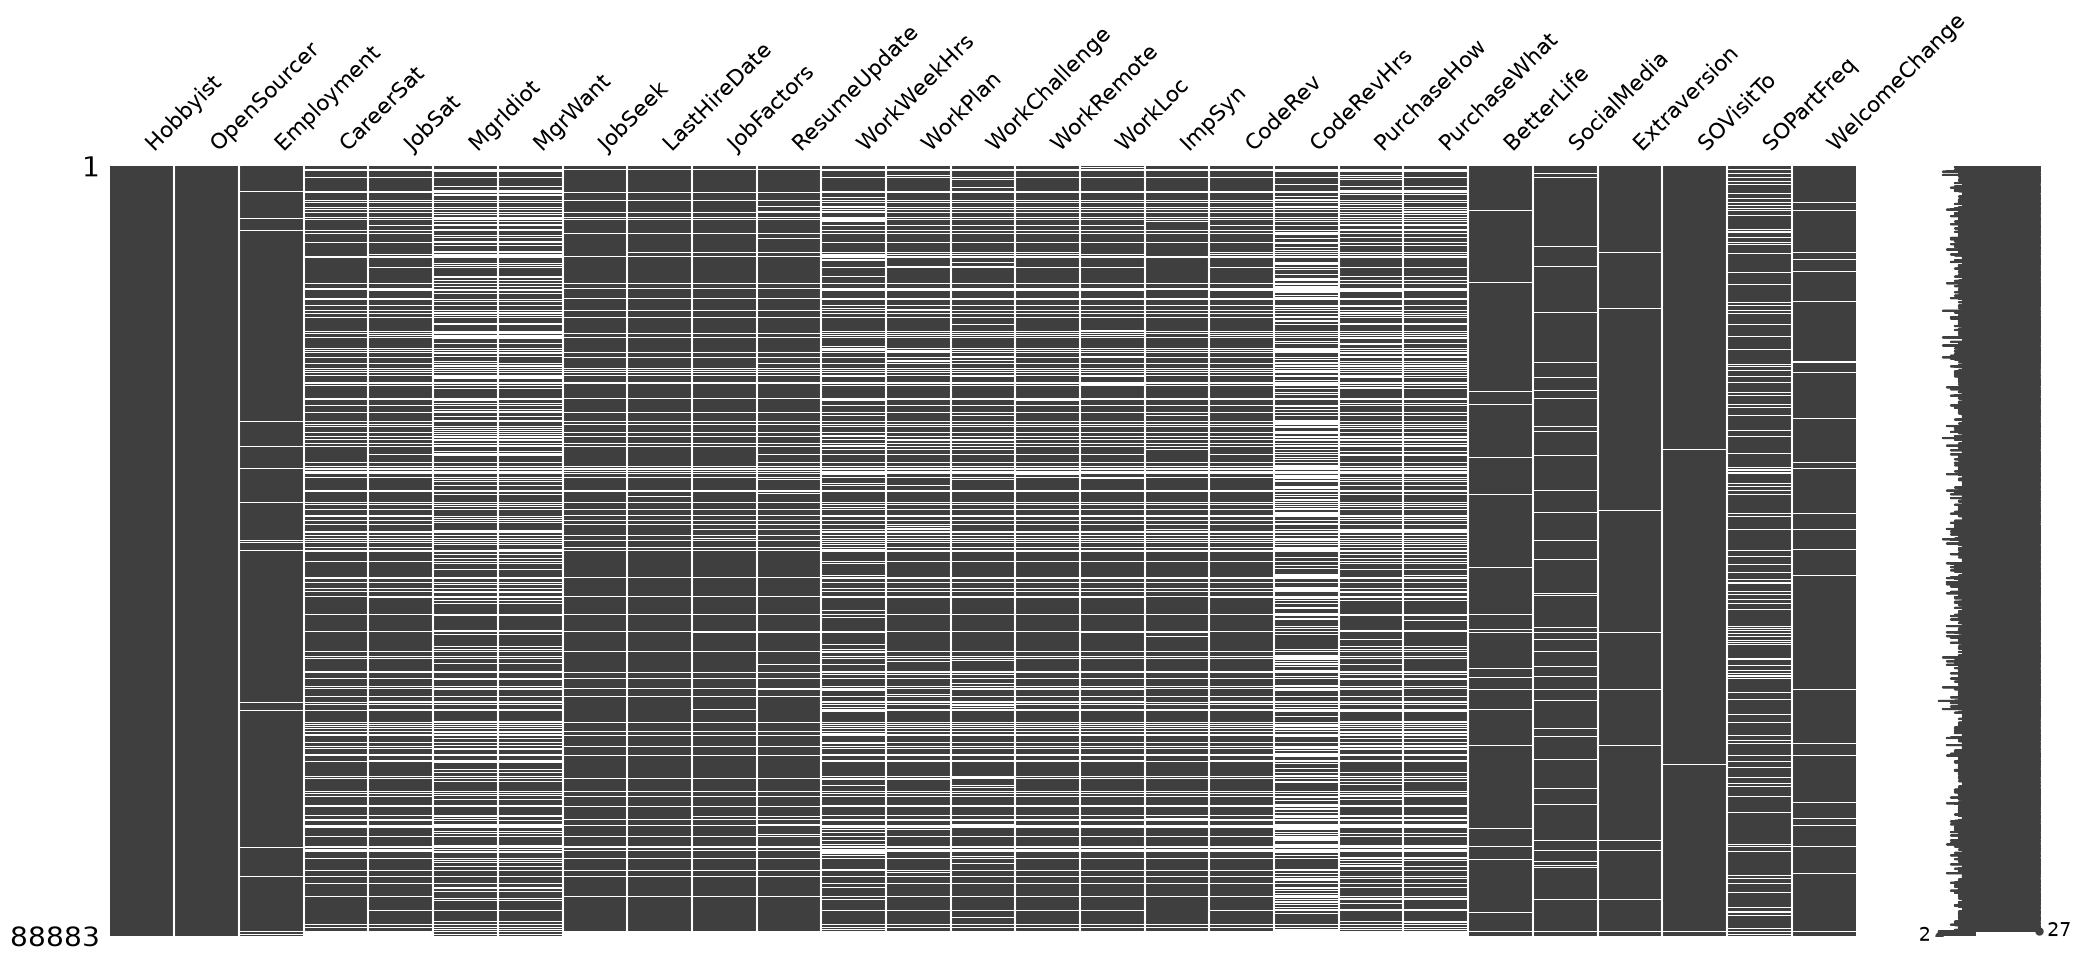

In [3]:
df_softskills.info()
msno.matrix(df_softskills)

### 1.4 Revisión de nulos y duplicados

En esta celda extraemos el porcentaje de datos incompletos por variable del *dataset*, lo cual es muy importante para poder tomar decisiones objetivas. 

1. **Cuantificación de Nulos:** mediante un gráfico de barras vemos el porcentaje exacto de información faltante, lo que ayuda a establecer umbrales críticos de decisión (por ejemplo, saber matemáticamente si una variable requiere imputación de datos o si su déficit es tan alto que debe ser eliminada por completo).

2. **Fuga de Datos (Duplicados):** vemos que tenemos un total de **5.053 filas duplicadas**. Si introducimos perfiles técnicos repetidos en nuestra futura Red Neuronal, el modelo sufrirá de *Overfitting* (sobreajuste), memorizando a esos candidatos en lugar de aprender a generalizar los perfiles.

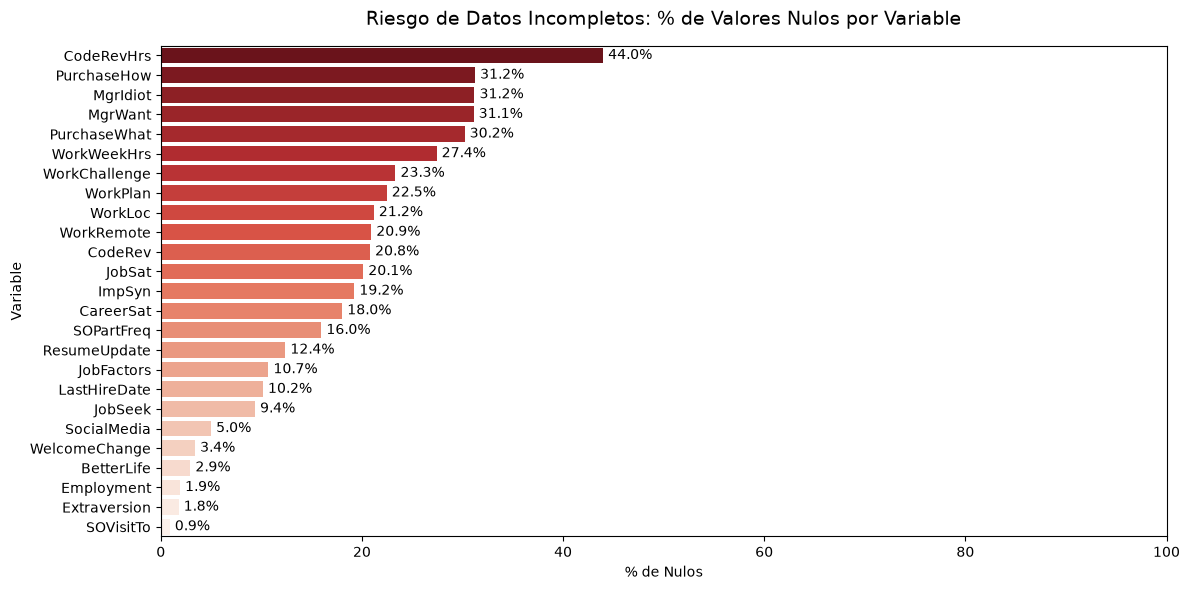


Revisión de integridad: Hay 1,176 filas duplicadas en el dataset original.


In [4]:
missing_percentage = df_softskills.isnull().mean() * 100
missing_percentage = missing_percentage[missing_percentage > 0].sort_values(ascending=False)

if not missing_percentage.empty:
    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=missing_percentage.values, 
        y=missing_percentage.index, 
        palette='Reds_r'
    )
    plt.title('Riesgo de Datos Incompletos: % de Valores Nulos por Variable', fontsize=14, pad=15)
    plt.xlabel('% de Nulos')
    plt.ylabel('Variable')
    for i, valor in enumerate(missing_percentage.values):
        plt.text(valor + 0.5, i, f"{valor:.1f}%", va='center', fontsize=10)
        
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()

num_duplicates = df_softskills.duplicated().sum()
print(f"\nRevisión de integridad: Hay {num_duplicates:,} filas duplicadas en el dataset original.")

### 1.5 Análisis estadístico descriptivo y detección de anomalías

En esta celda calculamos la media, desviación estándar, cuartiles y valores extremos para poder ver cuales son las *Top 5* de categorías más frecuentes para las columnas de texto. 

Este paso es muy importante porque nos cuenta la "historia" de los datos y revela anomalías a simple vista:

1. **El perfil predominante:** Gracias al recuento categórico, podemos observar, entre otras, que la mayoría de los candidatos de este dataset son empleados a tiempo completo.

2. **Detección de Outliers (Valores Atípicos):** Los estadísticos numéricos nos muestran señales de alarma clarísimas. Por ejemplo, en la variable (`WorkWeekHrs`) vemos un valor máximo de 4850h, y un mínimo de 1h. En la variable de horas de revisión del código (`CodeRevHrs`) hay algunos valores que superan a las horas semanales trabajadas. 

Estos valores extremos (intencionados o por error de tipeo en la encuesta) destruirían la distribución de pesos y el aprendizaje de la red. Esto justifica matemáticamente y de cara a negocio la necesidad de aplicar filtros restrictivos (*clipping*) en la siguiente fase de limpieza.

In [5]:
print("RESUMEN DE VARIABLES NUMÉRICAS:")
display(df_softskills.describe().T.round(2))

print("\n\nRESUMEN DE VARIABLES CATEGÓRICAS (Top 5 más frecuentes por columna):")
cat_cols = df_softskills.select_dtypes(include=['object', 'category']).columns

for col in cat_cols:
    print(f"\n--- {col} ---")
    display(df_softskills[col].value_counts().head(5).to_frame(name='Conteo'))

RESUMEN DE VARIABLES NUMÉRICAS:


,count,mean,std,min,25%,50%,75%,max
WorkWeekHrs,64503.0,42.13,37.29,1.0,40.0,40.0,44.75,4850.0
CodeRevHrs,49790.0,5.08,5.51,0.0,2.0,4.0,6.00,99.0




RESUMEN DE VARIABLES CATEGÓRICAS (Top 5 más frecuentes por columna):

--- Hobbyist ---


,Conteo
Hobbyist,
Yes,71257
No,17626



--- OpenSourcer ---


...

,Conteo
SOVisitTo,
Find answers to specific questions,33842
Find answers to specific questions;Learn how to do things I didn’t necessarily look for,15416
Find answers to specific questions;Contribute to a library of information,6955
Find answers to specific questions;Learn how to do things I didn’t necessarily look for;Contribute to a library of information,4265
Find answers to specific questions;Learn how to do things I didn’t necessarily look for;Pass the time / relax,3467



--- SOPartFreq ---


,Conteo
SOPartFreq,
Less than once per month or monthly,30440
I have never participated in Q&A on Stack Overflow,17287
A few times per month or weekly,14094
A few times per week,7040
Daily or almost daily,3695



--- WelcomeChange ---


,Conteo
WelcomeChange,
Just as welcome now as I felt last year,62661
Somewhat more welcome now than last year,8853
A lot more welcome now than last year,4808
Somewhat less welcome now than last year,4259
Not applicable - I did not use Stack Overflow last year,2675


### 1.6 Realizamos limpieza estricta

En esta celda aplicamos nuestra función `limpieza_datos`del módulo `utils`. Esta función realiza las siguientes tareas:

1. **Eliminación de fugas:** Borra los más de 5.000 perfiles duplicados que hemos visto antes.
2. **Filtrado de calidad:** Descarta candidatos "vacíos" que no hayan respondido a las preguntas clave sobre sus herramientas y tecnologías.
3. **Imputación Inteligente (Flags):** En lugar de borrar a los usuarios que no indicaron sus años de experiencia o herramientas, la función rellena los nulos con ceros y crea columnas bandera (ej. `WorkExp_is_missing`, visibles en la tabla resultante). Esto permite a la red neuronal entender que un cero no significa "cero años de experiencia", sino "el usuario no quiso facilitar este dato", capturando así un patrón de comportamiento sin perder al candidato.

*Resultado:* Hemos logrado retener a **44.061 candidatos** limios, formando un bloque sólido sobre el que construir el algoritmo NetSTAFF.

In [6]:
df_clean = utils_soft.limpieza_soft_skills_2019(df_softskills)
print(f"Transformaciones aplicadas. Candidatos mantenidos: {df_clean.shape[0]}")
display(df_clean.head(3))

Transformaciones aplicadas. Candidatos mantenidos: 87707


,Hobbyist,OpenSourcer,Employment,CareerSat,JobSat,MgrIdiot,MgrWant,JobSeek,LastHireDate,JobFactors,...,PurchaseHow,PurchaseWhat,BetterLife,SocialMedia,Extraversion,SOVisitTo,SOPartFreq,WelcomeChange,WorkWeekHrs_is_missing,CodeRevHrs_is_missing
Respondent,,,,,,,,,,,,,,,,,,,,,
1,Yes,Never,"Not employed, and not looking for work",Not Applicable,Not Applicable,Not Applicable,Not Applicable,Not Provided,Not Provided,NaN,...,Not Applicable,Not Applicable,Yes,Twitter,Online,Find answers to specific questions;Learn how t...,Not Provided,Just as welcome now as I felt last year,1,1
2,No,Less than once per year,"Not employed, but looking for work",Not Applicable,Not Applicable,Not Applicable,Not Applicable,I am actively looking for a job,I've never had a job,Financial performance or funding status of the...,...,Not Applicable,Not Applicable,Yes,Instagram,Online,Find answers to specific questions;Learn how t...,A few times per month or weekly,Just as welcome now as I felt last year,1,1
3,Yes,Never,Employed full-time,Slightly satisfied,Slightly satisfied,Not at all confident,Not sure,"I’m not actively looking, but I am open to new...",1-2 years ago,"Languages, frameworks, and other technologies ...",...,Not sure,I have little or no influence,Yes,Reddit,In real life (in person),Find answers to specific questions;Learn how t...,Less than once per month or monthly,Just as welcome now as I felt last year,0,1


## 2. Análisis visual de los datos

En esta sección vemos de forma más visual con gráficas los datos, aportando comparativas interesantes y descubriendo lo que los datos nos cuentan

### 2.1 Programar es una afición o solo un trabajo

En esta celda vemos si a los distintos candidatos les gusta programar como hobby o sólo lo considera su trabajo. Por otro lado queremos ver si contribuye a proyectos de código abierto con `OpenSourcer`, la cual nos dice si colabora en proyectos de forma desinteresada y le produce cierta motivación


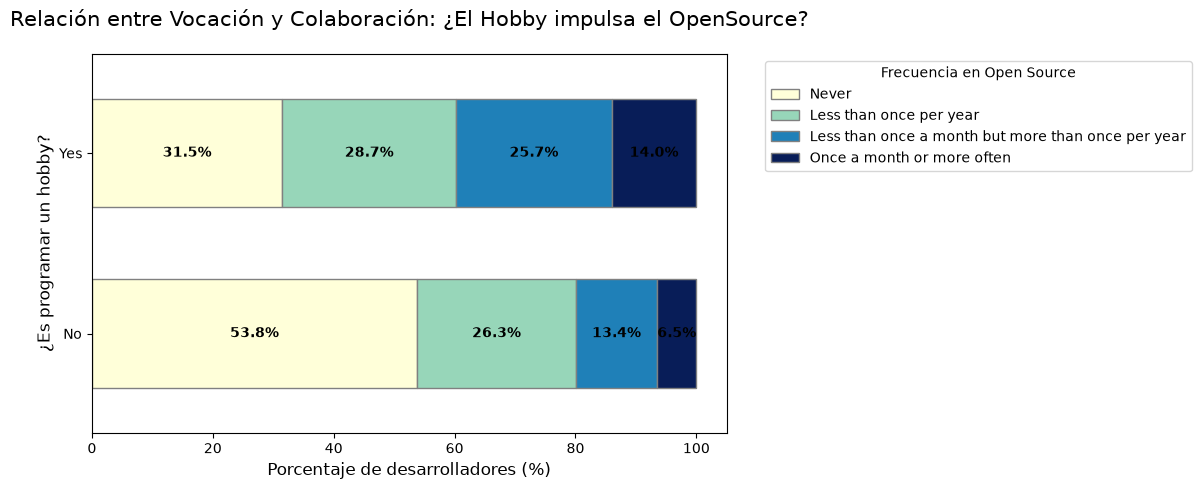

In [7]:
orden_os = list(config.OPENSOURCER_MAPPING.keys())

df_vocacion = df_clean[
    (df_clean['Hobbyist'].isin(['Yes', 'No'])) & 
    (df_clean['OpenSourcer'].isin(orden_os))
].copy()

tabla_cruzada_vocacion = pd.crosstab(df_vocacion['Hobbyist'], df_vocacion['OpenSourcer'], normalize='index') * 100
tabla_cruzada_vocacion = tabla_cruzada_vocacion.reindex(columns=orden_os)

fig, ax = plt.subplots(figsize=(12, 5))
tabla_cruzada_vocacion.plot(
    kind='barh', 
    stacked=True, 
    ax=ax, 
    colormap='YlGnBu', 
    edgecolor='gray',
    width=0.6
)

ax.set_title('Relación entre Vocación y Colaboración: ¿El Hobby impulsa el OpenSource?', fontsize=15, pad=20)
ax.set_xlabel('Porcentaje de desarrolladores (%)', fontsize=12)
ax.set_ylabel('¿Es programar un hobby?', fontsize=12)
plt.legend(title='Frecuencia en Open Source', bbox_to_anchor=(1.05, 1), loc='upper left')

for c in ax.containers:
    labels = [f'{v.get_width():.1f}%' if v.get_width() > 4 else '' for v in c]
    ax.bar_label(c, labels=labels, label_type='center', color='black', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

Como podemos observar, estas variables muestran mucha relación, ya que todos aquellos que no lo consideran un hobby no participan en proyectos OpenSource altruistas, si no que se mueven más por otras motivaciones más ligadas con negocios. Si comparamos a aquellos que consideran programar un hobby con los que no lo consideran, vemos que si sumamos las dos franjas azules (los que más colaboran) los que lo consideran un hobby son casi un 40% frente a los 20%  que lo consideran no.

ESta métrica nos muestra que si queremos un perfil colaborativo, proactivo y que comparta conocimiento, que considere la programación un hobby puede ayudarnos a encontrar el candidato ideal.

### 2.2 La satisfacción de los candidatos

Para esta siguiente gráfica queremos saber el nivel de satisfacción actual de un candidato. Un candidato insatisfecho suele presentar menor dificultad a la hora de buscar un cambio, pero debemos de saber que relación guarda con lo insatisfecho que está con sus estudios o preparación posterior. Esto es un buen indicativo, ya que puede que su descontento sea con las condiciones de su puesto actual de trabajo, no con el área o ámbito al que se dedica.

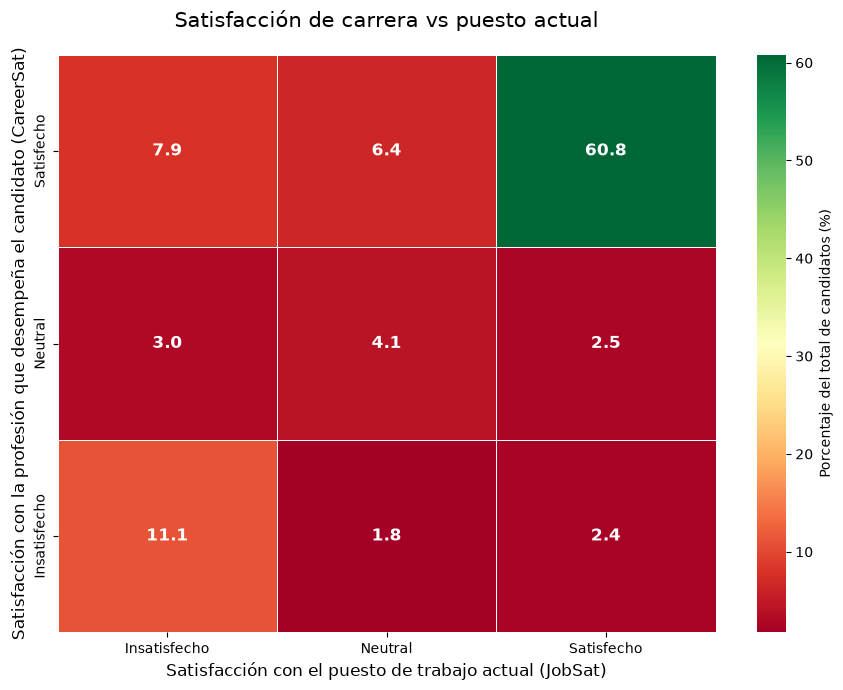

In [8]:
listado_satifaccion = list(config.SATISFACCION_MAPPING.keys())

df_sat = df_clean.copy()
df_sat['JobSat_Group'] = df_sat['JobSat'].map(config.SATISFACCION_MAPPING)
df_sat['CareerSat_Group'] = df_sat['CareerSat'].map(config.SATISFACCION_MAPPING)

# Filtrar a los que sí respondieron a ambas (quitamos desempleados o nulos)
df_satisfaccion_nonull = df_sat.dropna(subset=['JobSat_Group', 'CareerSat_Group'])
sat_matrix = pd.crosstab(df_satisfaccion_nonull['CareerSat_Group'], df_satisfaccion_nonull['JobSat_Group'], normalize='all') * 100

orden = ['Insatisfecho', 'Neutral', 'Satisfecho']
sat_matrix = sat_matrix.reindex(index=orden, columns=orden)

plt.figure(figsize=(9, 7))
sns.heatmap(
    sat_matrix, 
    annot=True, 
    fmt=".1f",
    cmap="RdYlGn",
    linewidths=.5,
    cbar_kws={'label': 'Porcentaje del total de candidatos (%)'},
    annot_kws={"size": 12, "weight": "bold"}
)

plt.title('Satisfacción de carrera vs puesto actual', fontsize=15, pad=20)
plt.xlabel('Satisfacción con el puesto de trabajo actual (JobSat)', fontsize=12)
plt.ylabel('Satisfacción con la profesión que desempeña el candidato (CareerSat)', fontsize=12)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

Si observamos el mapa de calor, vemos que el 60.5% de todos los candidatos están satisfechos con su profesión y con su puesto de trabajo actual. Esto es una cifra muy alta que muestra que la mayoría de profesionales no estarían dispuestos a un cambio por cualquier cosa, si no que reclutar profesionales puede ser de mayor esfuerzo, por ejemplo, se requieren mayores subidas salariales o buscan proyectos específicos que les proporcione mucha motivación.

Si observamos todos aquellos que están satisfechos con su carrera pero no con su trabajo actual, vemos a personas que les apasiona desarrollar pero no están nada contentos con sus condiciones de trabajo. Estos candidatos presentarán mayor facilidad para el cambio y puede que nos resulten de un alto interés.

Por otra parte, todos aquellos que no están satisfechos con sus estudios vemos que es muy complicado que estén motivados por su trabajo actual o por ningún otro. Estas personas puede ser arriesgado considerarlas, ya que su falta de motivación puede afectar a su rendimiento a corto o largo plazo.

### 2.3 Opinión de los responsables y autoridad

Para que el sistema elija a los candidatos de forma inteligente, no sólo debemos emparejarlos con un proyecto determinado, si no que tenemos que fijarnos en el rol. Es posible que un desarrollador brillante no quiera ser manager y si decidimos asignarlo como responsable de un equipo perdamos a un buen técnico y ganemos un mal líder.

Para ello nos fijamos en dos cosas, dos datos que nos ofrece el dataset:

* La opinión de los responsables con `MgrIdiot` nos permite ver el nivel de confianza que tienen los técnicos con respeto a sus responsables, lo que también nos muestra el respeto hacia sus superiores.
* `MrgWant` señala cuánto desean los técnicos asceneder y convertirse en mánager, es decir, la ambición de liderazgo que poseen
* `PurchaseHow` y `PurchaseWhat` nos permiten saber el nivel de influencia a la hora de comprar tecnología, es decir, el impacto en la empresa o la capacidad de persuasión.


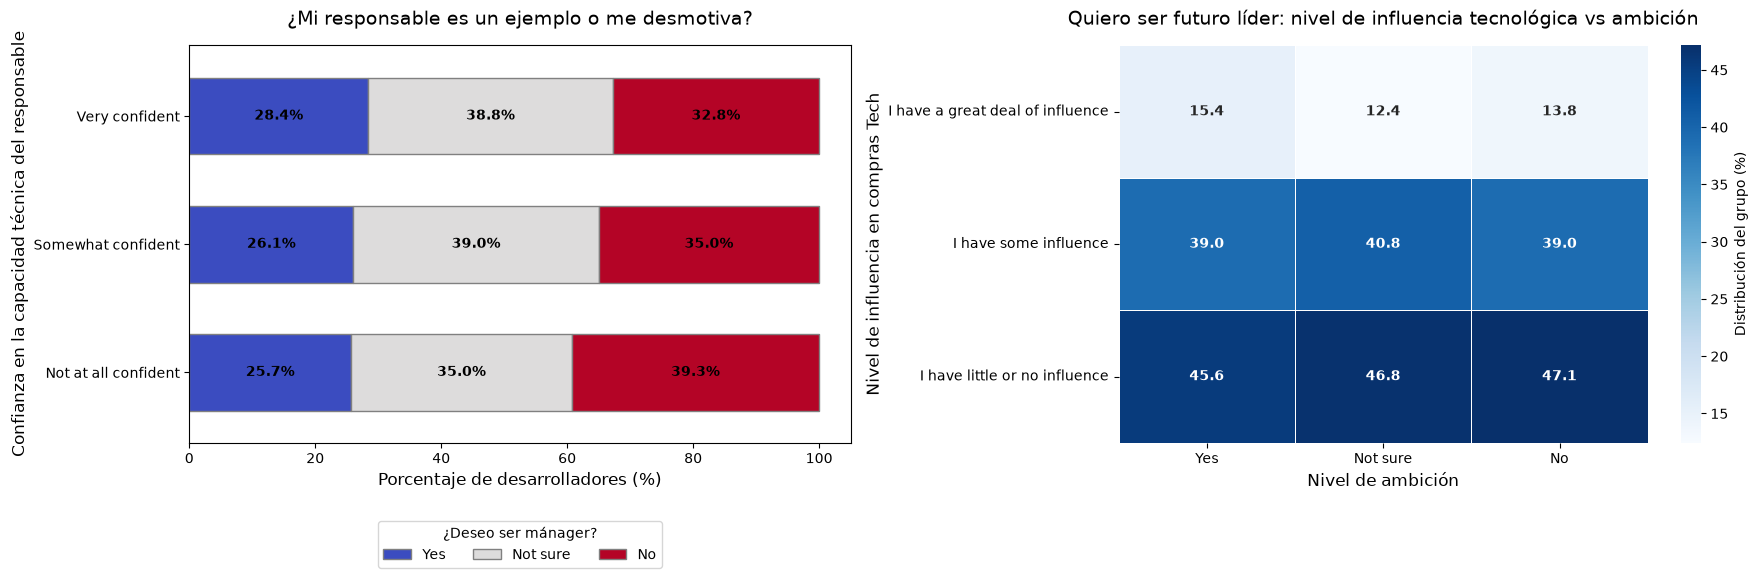

In [9]:
listado_orden_idiot = list(config.IDIOT_MAPPING.keys())
listado_orden_want = list(config.WANT_MAPPING.keys())
listado_orden_infl = list(config.INFLUENCIA_MAPPING.keys())

df_jefe = df_clean[
    (df_clean['MgrIdiot'].isin(listado_orden_idiot)) & 
    (df_clean['MgrWant'].isin(listado_orden_want))
].copy()

tabla_cruzada_jefe = pd.crosstab(df_jefe['MgrIdiot'], df_jefe['MgrWant'], normalize='index') * 100
tabla_cruzada_jefe = tabla_cruzada_jefe.reindex(index=listado_orden_idiot, columns=listado_orden_want)

df_influencia = df_clean[
    (df_clean['MgrWant'].isin(listado_orden_want)) & 
    (df_clean['PurchaseWhat'].isin(listado_orden_infl))
].copy()

tabla_cruzada_influencia = pd.crosstab(df_influencia['PurchaseWhat'], df_influencia['MgrWant'], normalize='columns') * 100
tabla_cruzada_influencia = tabla_cruzada_influencia.reindex(index=listado_orden_infl, columns=listado_orden_want)

fig, (ax1, ax2) = plt.subplots(1, 2,figsize=(18, 6))

tabla_cruzada_jefe.plot(
    kind='barh', stacked=True, ax=ax1, colormap='coolwarm', edgecolor='gray', width=0.6
)
ax1.set_title('¿Mi responsable es un ejemplo o me desmotiva?', fontsize=14, pad=15)
ax1.set_xlabel('Porcentaje de desarrolladores (%)', fontsize=12)
ax1.set_ylabel('Confianza en la capacidad técnica del responsable', fontsize=12)
ax1.legend(title='¿Deseo ser mánager?', bbox_to_anchor=(0.5, -0.18), loc='upper center', ncol=3)
ax1.invert_yaxis()

for c in ax1.containers:
    labels = [f'{v.get_width():.1f}%' if v.get_width() > 5 else '' for v in c]
    ax1.bar_label(c, labels=labels, label_type='center', color='black', fontweight='bold', fontsize=10)

sns.heatmap(
    tabla_cruzada_influencia, annot=True, fmt=".1f", cmap="Blues", linewidths=.5,
    cbar_kws={'label': 'Distribución del grupo (%)'}, ax=ax2, annot_kws={"weight": "bold"}
)
ax2.set_title('Quiero ser futuro líder: nivel de influencia tecnológica vs ambición', fontsize=14, pad=15)
ax2.set_xlabel('Nivel de ambición', fontsize=12)
ax2.set_ylabel('Nivel de influencia en compras Tech', fontsize=12)
ax2.invert_yaxis()

plt.tight_layout()
plt.show()

Si observamos estas gráficas, vemos 3 patrones principales:

* La gran mayoría de desarrolladores no tienen un deseo claro de ser mánagers. En todos los escenarios vistos vemos que si sumamos a todos aquellos que no quieren ser mánagers (las barras rojas) y los que no lo tienen claro (barra gris) supera ampliamente el 70% del total. Con estos perfiles, obligar a un perfil técnico a asumir un rol de gestión puede ser un error muy importante que debemos evitar.

* Muchos de los candidatos que no confían demasiado en sus responsables produce mayor rechazo hacia este rol. Por el contrario, todos aquellos que confían en sus responsables tienden a tener un mayor porcentaje de ambición y les gustaría más tomar estos roles con mayor responsabilidad, por lo que el nivel de confianza en sus managers presenta cierta influencia.

* Al analizar el mapa de calor, vemos que la ambición directiva está correlacionada con la proactividad. El grupo de profesionales que sí quiere ser mánager concentra un mayor nivel de incluencia en decisiones de compras tecnológicas.

### 2.4 La experiencia y las ofertas

Para esta siguiente gráfica vemos con cuantos años de experiencia en su puesto actual tienen un pensamieto de cambio de puesto o de rol. Aquí hay 3 casos, aquellos que son pasivos y están abiertos a ofertas, aquellos que están en búsqueda constante y los que no contemplan un cambio

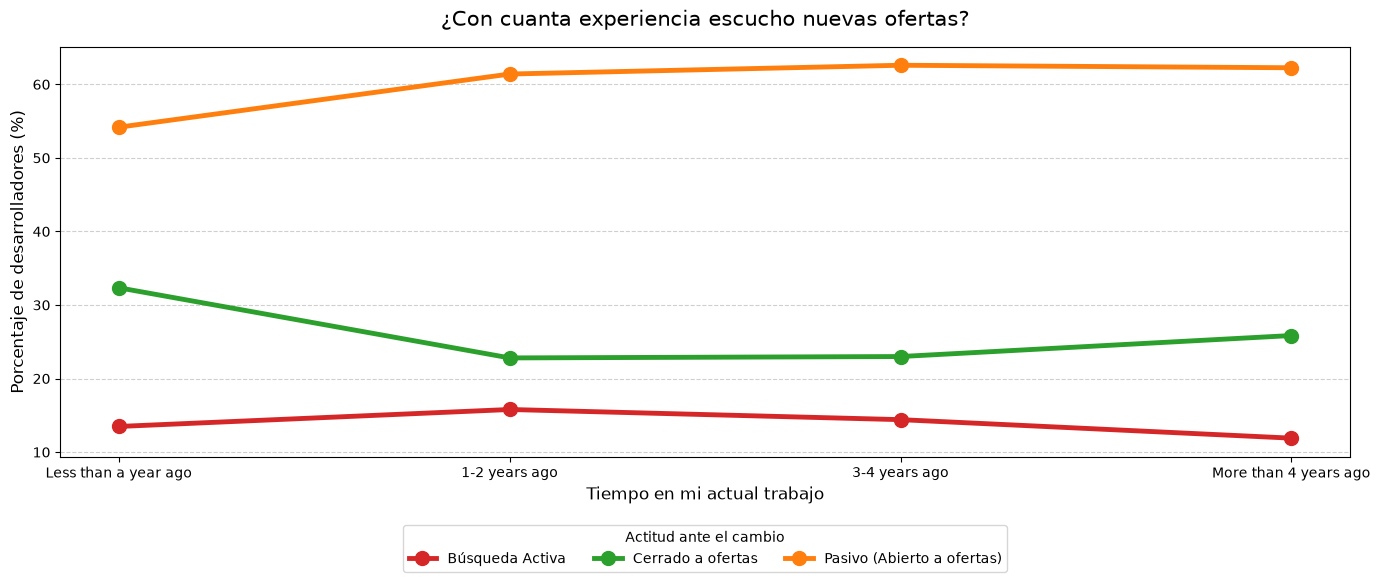

In [10]:
listado_orden_hire = list(config.ORDEN_HIRE)
mapeo_busqueda = config.MAPEO_SEEK

df_carrera = df_clean.copy()
df_carrera['busqueda_empleo'] = df_carrera['JobSeek'].map(mapeo_busqueda)

df_carrera = df_carrera[
    (df_carrera['LastHireDate'].isin(listado_orden_hire)) & 
    (df_carrera['busqueda_empleo'].notnull()) &
    (df_carrera['ResumeUpdate'].notnull())
]

crosstab_hire = pd.crosstab(df_carrera['LastHireDate'], df_carrera['busqueda_empleo'], normalize='index') * 100
crosstab_hire = crosstab_hire.reindex(index=listado_orden_hire)

fig, ax1 = plt.subplots(figsize=(14, 6))

estados = {
    'Búsqueda Activa': '#d62728',
    'Pasivo (Abierto a ofertas)': '#ff7f0e',
    'Cerrado a ofertas': '#2ca02c'
}

for columna in crosstab_hire.columns:
    ax1.plot(
        crosstab_hire.index, 
        crosstab_hire[columna], 
        marker='o', 
        linewidth=3.5, 
        markersize=10, 
        label=columna, 
        color=estados[columna]
    )

ax1.set_title('¿Con cuanta experiencia escucho nuevas ofertas?', fontsize=15, pad=15)
ax1.set_ylabel('Porcentaje de desarrolladores (%)', fontsize=12)
ax1.set_xlabel('Tiempo en mi actual trabajo', fontsize=12)
ax1.legend(title='Actitud ante el cambio', bbox_to_anchor=(0.5, -0.15), loc='upper center', ncol=3)
ax1.grid(axis='y', linestyle='--', alpha=0.6) 

plt.tight_layout()
plt.show()

Esta gráfica nos muestra, que el caso más común es aquel en la cual los profesionales no buscan, pero no se cierran a cambios, siendo la búsqueda activa la menos común. Cuantos más años pasan, vemos que los candidatos tienen a buscar menos cambio o búsqueda y se centran en un estado pasivo, sin cerrarse a oportunidades nuevas.

### 2.5 Motivos para actualizar el CV

En esta velda tratamos de ver los principales motivos por los cuales los desarrolladores se ven motivados a cambiaar su CV y, por lo tanto, podrían estar más abiertos a un cambio de compañía. EL objetivo aquí es diferenciar entre la actualización cotidiana y aquellos que lo actualizan por que quieren abrirse a nuevos puestos.

Diferenciamos por cada uno de los diferentes motivos y la actitud al cambio para cada uno ellos.

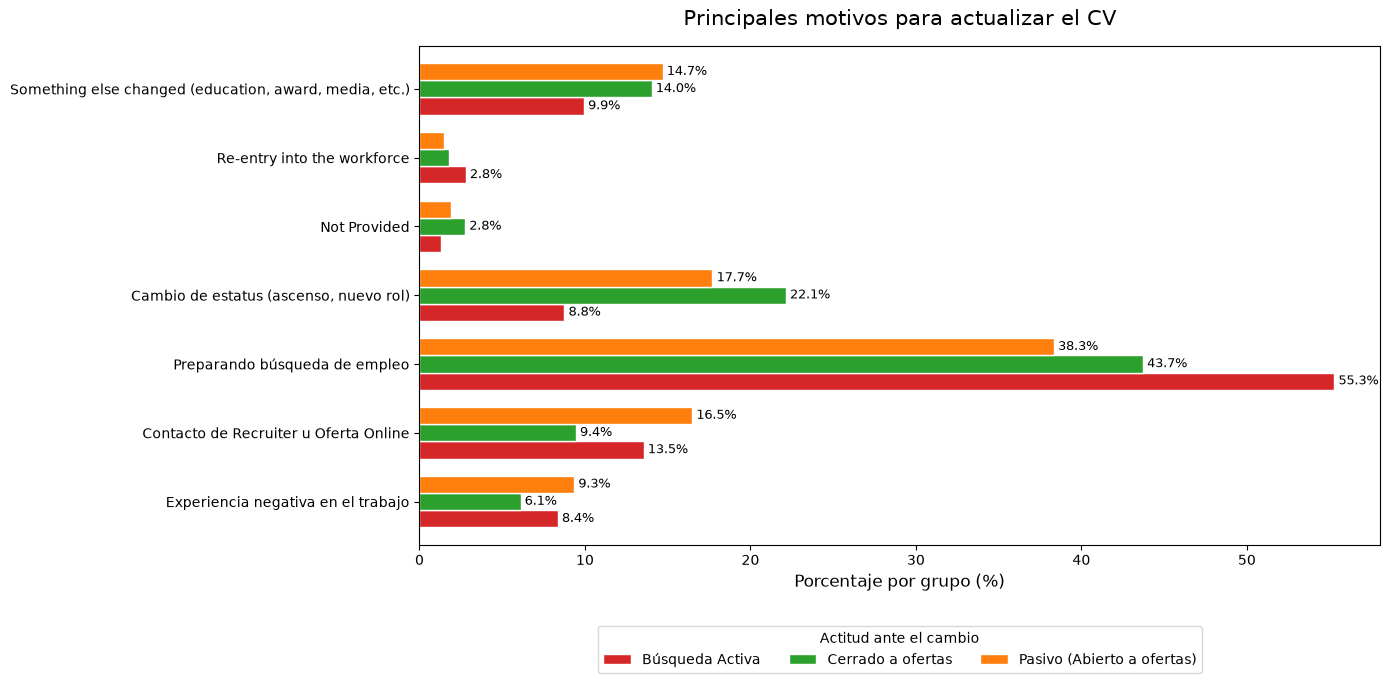

In [11]:
mapeo_resume = config.MAPEO_RESUME_UPDATE
tabla_cruzada_resume = pd.crosstab(df_carrera['ResumeUpdate'], df_carrera['busqueda_empleo'], normalize='columns') * 100
tabla_cruzada_resume = tabla_cruzada_resume.rename(index=mapeo_resume)

fig, ax2 = plt.subplots(figsize=(14, 7))

tabla_cruzada_resume.plot(
    kind='barh', 
    ax=ax2, 
    color=[estados[c] for c in tabla_cruzada_resume.columns], 
    width=0.75,
    edgecolor='white'
)

ax2.set_title('Principales motivos para actualizar el CV', fontsize=15, pad=15)
ax2.set_xlabel('Porcentaje por grupo (%)', fontsize=12)
ax2.set_ylabel('')
ax2.legend(title='Actitud ante el cambio', bbox_to_anchor=(0.5, -0.15), loc='upper center', ncol=3)

for c in ax2.containers:
    labels = [f'{v.get_width():.1f}%' if v.get_width() > 2 else '' for v in c]
    ax2.bar_label(c, labels=labels, padding=3, color='black', fontsize=9)

plt.tight_layout() 
plt.show()

Como podemos var si observamos la búsqueda activa, esta claro que la mayoría (el 55.3%) cambian su CV porque quieren buscar un cambio laboral o personal. Este cambio no es rutinario, si no que actualizan motivados a esta decisión.

Por otro lado, tenemos a los que se cierran a ofertas, los cuales el motivo en el que destacan es por que cambian de rol dentro de su compaía, por lo que estos profesionales lo hacen para reflejar sus logros y para su mantenimiento profesional.

Para los usuarios pasivos, vemos que destacan cuando contactan con un recruiter o reciben una oferta online, lo cual demuestra que cambian su cv si reciben una oferta atractiva y motivadora

### 2.6 Los motivos del cambio

A la hora de cambiar de empleo y buscar que candidatos son más fáciles que acepten una oferta o nuevo rol, debemos saber los principales motivos por los cuales los profesionales consideran dejar su puesto actual y miran hacia un cambio

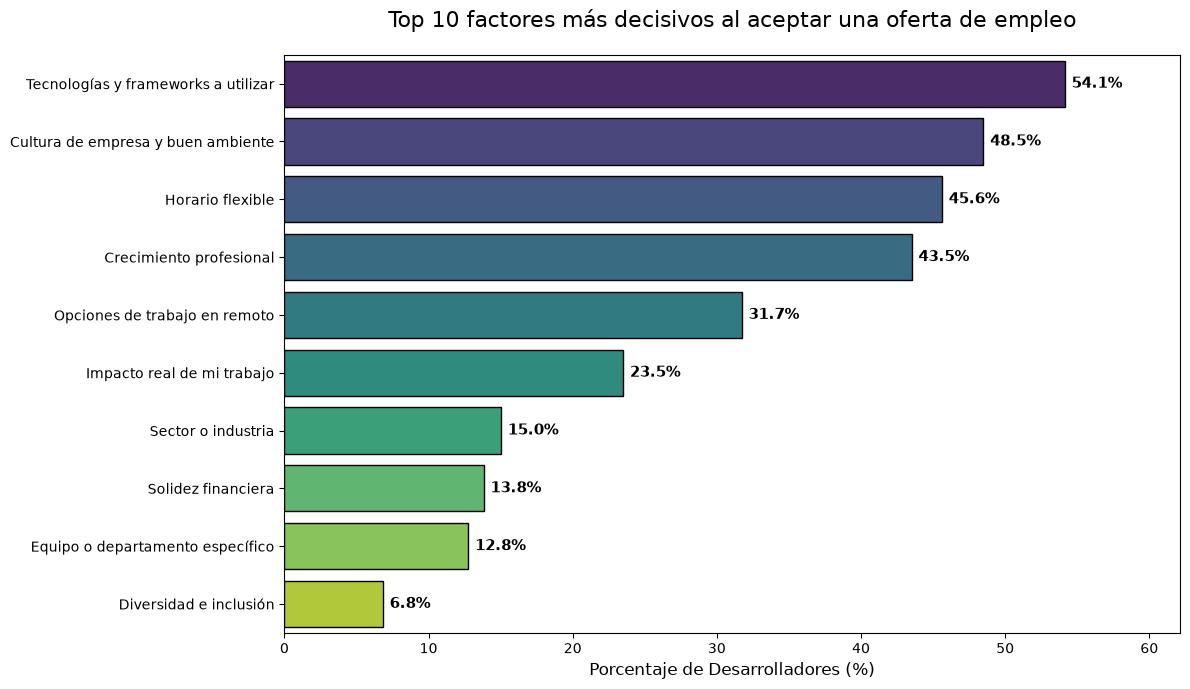

In [12]:
mapeo_factores = config.MAPEO_FACTORES

factores_individuales = df_clean['JobFactors'].dropna().astype(str).str.split(';').explode()
factores_individuales = factores_individuales.str.strip()
conteo = factores_individuales.value_counts().head(10)
total_personas = df_clean['JobFactors'].dropna().shape[0]

df_top = pd.DataFrame({
    'Factor_EN': conteo.index,
    'Votos': conteo.values
})
df_top['Porcentaje'] = (df_top['Votos'] / total_personas) * 100
df_top['Factor_ES'] = df_top['Factor_EN'].map(mapeo_factores).fillna(df_top['Factor_EN'])

fig, ax = plt.subplots(figsize=(12, 7))

sns.barplot(
    x='Porcentaje', 
    y='Factor_ES', 
    data=df_top, 
    palette='viridis',
    edgecolor='black',
    ax=ax
)
ax.set_title('Top 10 factores más decisivos al aceptar una oferta de empleo', fontsize=16, pad=20)
ax.set_xlabel('Porcentaje de Desarrolladores (%)', fontsize=12)
ax.set_ylabel('')

for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%', padding=5, color='black', fontweight='bold', fontsize=11)
ax.set_xlim(0, df_top['Porcentaje'].max() + 8)

plt.tight_layout()
plt.show()

Como podemos observar, lo princpal y más importante de todo es la tecnología y frameworks con los que trabajan. Esto es importante ya que está relacionado con su nivel de experiencia, motivación y también las ganas de aprender otras herramientas diferentes a las actuales.

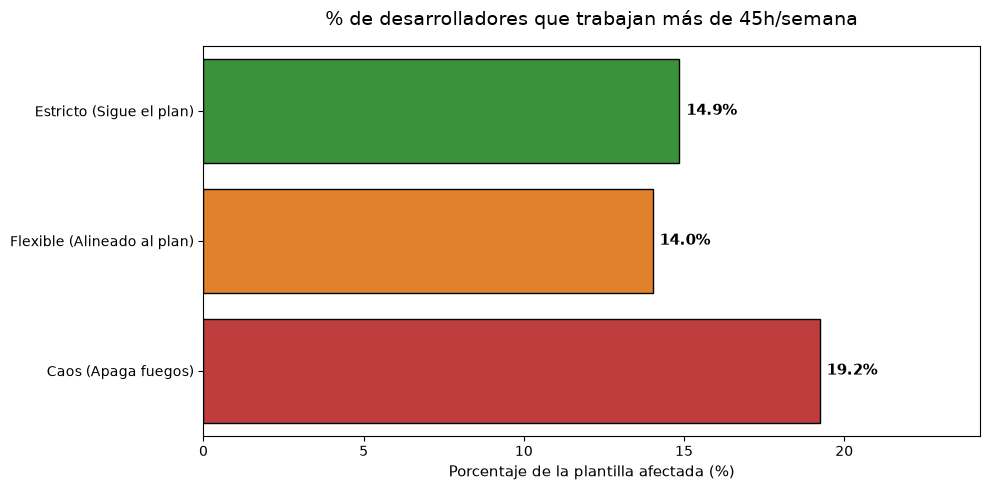

In [13]:
df_habitos = df_clean.copy()

def mapear_plan(texto):
    texto = str(texto).lower()
    if 'closely' in texto:
        return 'Estricto (Sigue el plan)'
    elif 'somewhat' in texto:
        return 'Flexible (Alineado al plan)'
    elif texto != 'nan':
        return 'Caos (Apaga fuegos)'
    return None

df_habitos['WorkPlan_ES'] = df_habitos['WorkPlan'].apply(mapear_plan)
df_habitos = df_habitos.dropna(subset=['WorkPlan_ES', 'WorkWeekHrs'])
df_habitos = df_habitos[(df_habitos['WorkWeekHrs'] >= 20) & (df_habitos['WorkWeekHrs'] <= 80)]


df_habitos['Burnout_Score'] = (df_habitos['WorkWeekHrs'] > 45).astype(int) * 100
burnout_por_grupo = df_habitos.groupby('WorkPlan_ES')['Burnout_Score'].mean().reindex(
    ['Estricto (Sigue el plan)', 'Flexible (Alineado al plan)', 'Caos (Apaga fuegos)']
).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5))
sns.barplot(
    x='Burnout_Score', 
    y='WorkPlan_ES', 
    data=burnout_por_grupo, 
    palette=['#2ca02c', '#ff7f0e', '#d62728'], 
    edgecolor='black',
    ax=ax1
)

ax1.set_title('% de desarrolladores que trabajan más de 45h/semana', fontsize=14, pad=15)
ax1.set_xlabel('Porcentaje de la plantilla afectada (%)', fontsize=11)
ax1.set_ylabel('')
for c in ax1.containers:
    ax1.bar_label(c, fmt='%.1f%%', padding=5, color='black', fontweight='bold', fontsize=11)

ax1.set_xlim(0, burnout_por_grupo['Burnout_Score'].max() + 5)

plt.tight_layout()
plt.show()

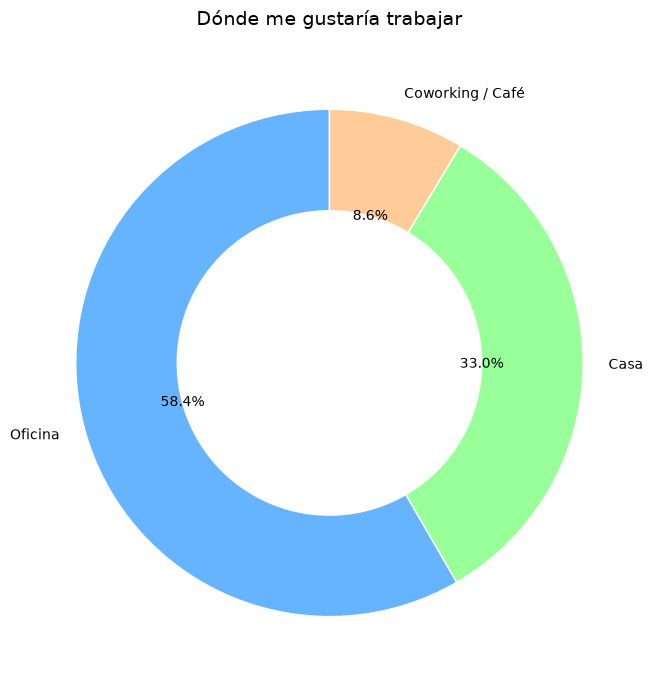

In [14]:
df_habitos['WorkLoc_ES'] = df_habitos['WorkLoc'].map(config.MAPEO_LOC)
conteo_loc = df_habitos['WorkLoc_ES'].value_counts()

fig, ax2 = plt.subplots(figsize=(7, 7))
ax2.pie(
    conteo_loc, 
    labels=conteo_loc.index, 
    autopct='%1.1f%%', 
    startangle=90, 
    colors=['#66b3ff', '#99ff99', '#ffcc99'],
    wedgeprops=dict(width=0.4, edgecolor='w')
)
ax2.set_title('Dónde me gustaría trabajar', fontsize=14, pad=15)

plt.tight_layout()
plt.show()

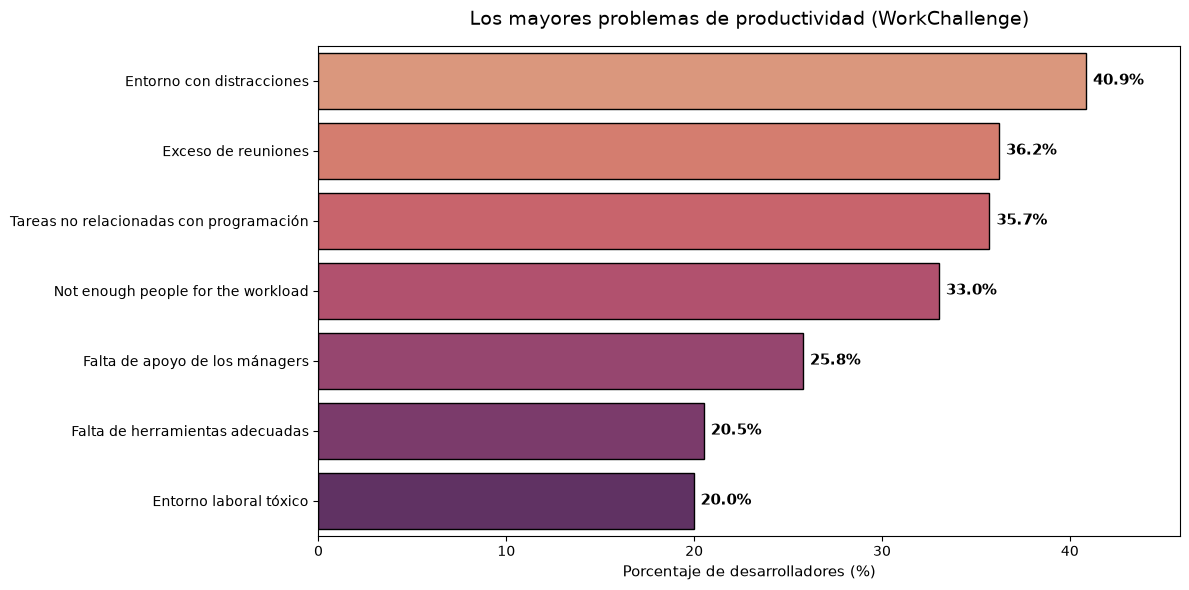

In [15]:
retos_individuales = df_habitos['WorkChallenge'].dropna().astype(str).str.split(';').explode()
retos_individuales = retos_individuales.str.strip()

conteo_retos = retos_individuales.value_counts().head(7)
total_personas_retos = df_habitos['WorkChallenge'].dropna().shape[0]

df_top_retos = pd.DataFrame({
    'Reto_EN': conteo_retos.index,
    'Votos': conteo_retos.values
})

df_top_retos['Porcentaje'] = (df_top_retos['Votos'] / total_personas_retos) * 100
df_top_retos['Reto_ES'] = df_top_retos['Reto_EN'].map(config.MAPEO_RETOS).fillna(df_top_retos['Reto_EN'])

fig, ax3 = plt.subplots(figsize=(12, 6))
sns.barplot(
    x='Porcentaje', 
    y='Reto_ES', 
    data=df_top_retos, 
    palette='flare', 
    edgecolor='black',
    ax=ax3
)
ax3.set_title('Los mayores problemas de productividad (WorkChallenge)', fontsize=14, pad=15)
ax3.set_xlabel('Porcentaje de desarrolladores (%)', fontsize=11)
ax3.set_ylabel('')

for c in ax3.containers:
    ax3.bar_label(c, fmt='%.1f%%', padding=5, color='black', fontweight='bold', fontsize=11)
ax3.set_xlim(0, df_top_retos['Porcentaje'].max() + 5)

plt.tight_layout()
plt.show()

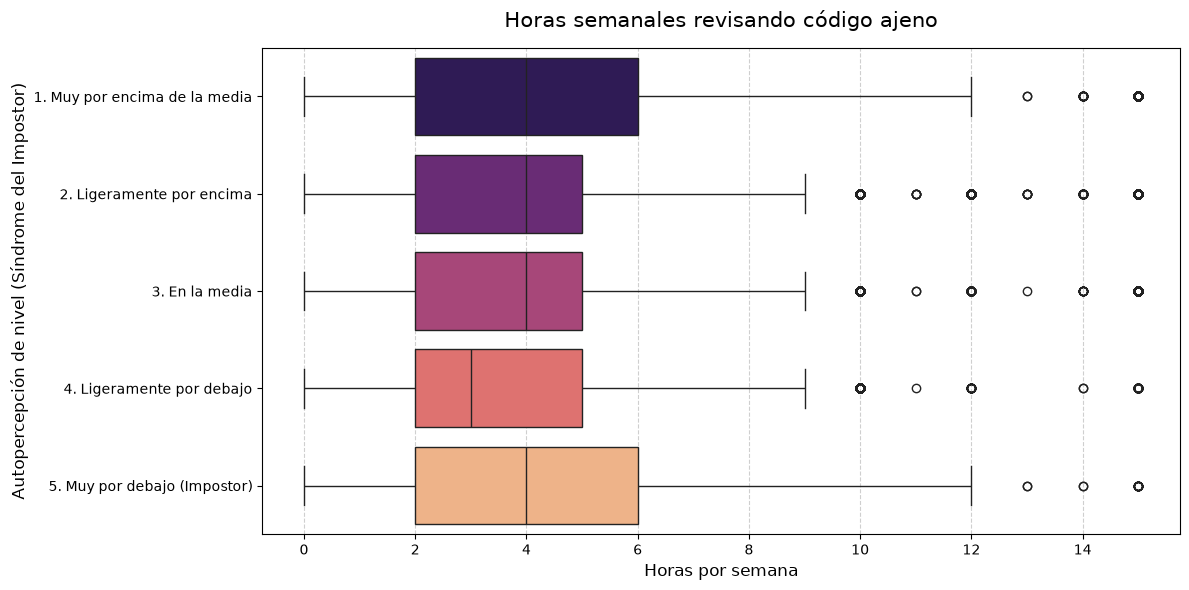

In [16]:
df_equipo = df_clean.dropna(subset=['ImpSyn', 'CodeRev']).copy()

df_equipo['ImpSyn_ES'] = df_equipo['ImpSyn'].map(config.MAPEO_IMP)
df_equipo['CodeRev_ES'] = df_equipo['CodeRev'].map(config.MAPEO_REV)

df_equipo_hrs = df_equipo[(df_equipo['CodeRevHrs'] >= 0) & (df_equipo['CodeRevHrs'] <= 15)]

orden_imp = sorted(list(config.MAPEO_IMP.values()))
fig, ax1 = plt.subplots(figsize=(12, 6))

sns.boxplot(
    x='CodeRevHrs', 
    y='ImpSyn_ES', 
    data=df_equipo_hrs, 
    ax=ax1, 
    palette='magma',
    order=orden_imp
)

ax1.set_title('Horas semanales revisando código ajeno', fontsize=15, pad=15)
ax1.set_xlabel('Horas por semana', fontsize=12)
ax1.set_ylabel('Autopercepción de nivel (Síndrome del Impostor)', fontsize=12)
ax1.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### 2.11 Revisión del código y síndrome del impostor

El objetivo de esta gráfica es entender cómo la autopercepción del desarrollador (su nivel de confianza o la presencia del Síndrome del Impostor) afecta a su disposición para auditar el trabajo de sus compañeros.

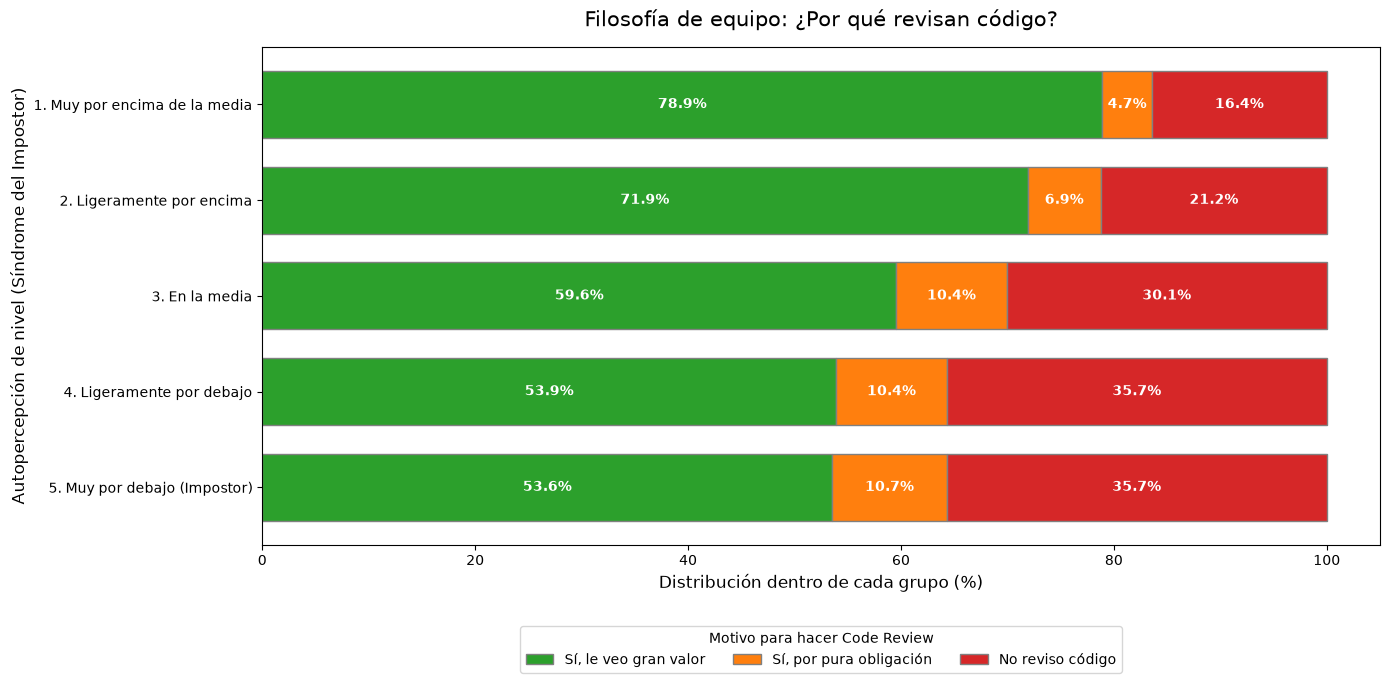

In [17]:
def mapear_revision(texto):
    texto = str(texto).lower()
    if 'value' in texto:
        return 'Sí, le veo gran valor'
    elif 'told' in texto:
        return 'Sí, por pura obligación'
    elif 'no' == texto.strip() or 'no ' in texto:
        return 'No reviso código'
    return None

df_equipo['CodeRev_ES'] = df_equipo['CodeRev'].apply(mapear_revision)
df_equipo_limpio = df_equipo.dropna(subset=['CodeRev_ES'])
crosstab_rev = pd.crosstab(df_equipo_limpio['ImpSyn_ES'], df_equipo_limpio['CodeRev_ES'], normalize='index') * 100

columnas_rev = ['Sí, le veo gran valor', 'Sí, por pura obligación', 'No reviso código']
crosstab_rev = crosstab_rev.reindex(index=orden_imp, columns=columnas_rev)

fig, ax2 = plt.subplots(figsize=(14, 7))

colores_rev = ['#2ca02c', '#ff7f0e', '#d62728']

crosstab_rev.plot(
    kind='barh', 
    stacked=True, 
    ax=ax2, 
    color=colores_rev, 
    edgecolor='gray', 
    width=0.7
)

ax2.set_title('Filosofía de equipo: ¿Por qué revisan código?', fontsize=15, pad=15)
ax2.set_xlabel('Distribución dentro de cada grupo (%)', fontsize=12)
ax2.set_ylabel('Autopercepción de nivel (Síndrome del Impostor)', fontsize=12)
ax2.legend(title='Motivo para hacer Code Review', bbox_to_anchor=(0.5, -0.15), loc='upper center', ncol=3)
ax2.invert_yaxis() 

for c in ax2.containers:
    labels = [f'{v.get_width():.1f}%' if v.get_width() > 4 else '' for v in c]
    ax2.bar_label(c, labels=labels, label_type='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

Esta gráfica nos muestra resultados muy relevantes:



### 2.12 Optimismo vs. sentido de pertenencia

Aquí queremos entender cómo de relacionadas están la opinión de desarrollador de si la tecnología es favorable a nuestro futuro y cómo de integrado se siente dentro de la comunidad. Esto nos puede ser útil a nivel psicológico, ya que si se siente más integrado también será más participativo y puede contribuir más a los proyectos.

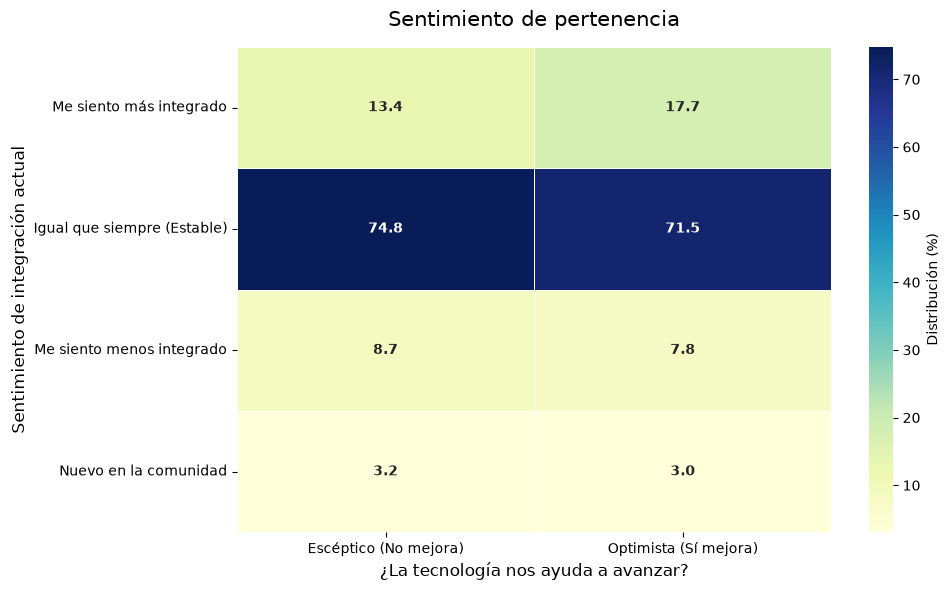

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_vision = df_clean.dropna(subset=['WelcomeChange', 'BetterLife']).copy()

df_vision['WelcomeChange_ES'] = df_vision['WelcomeChange'].map(config.MAPEO_WELCOME)
df_vision['BetterLife_ES'] = df_vision['BetterLife'].map(config.MAPEO_VIDA)
crosstab_vision = pd.crosstab(df_vision['WelcomeChange_ES'], df_vision['BetterLife_ES'], normalize='columns') * 100

orden_welcome = ['Me siento más integrado', 'Igual que siempre (Estable)', 'Me siento menos integrado', 'Nuevo en la comunidad']
crosstab_vision = crosstab_vision.reindex(index=orden_welcome)
fig, ax1 = plt.subplots(figsize=(10, 6))

sns.heatmap(
    crosstab_vision, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=.5,
    cbar_kws={'label': 'Distribución (%)'}, ax=ax1, annot_kws={"weight": "bold"}
)

ax1.set_title('Sentimiento de pertenencia', fontsize=15, pad=15)
ax1.set_xlabel('¿La tecnología nos ayuda a avanzar?', fontsize=12)
ax1.set_ylabel('Sentimiento de integración actual', fontsize=12)

plt.tight_layout()
plt.show()

Tras observar la gráfica:

* Vemos que lo más normal es Igual que siempre, ya que independientemente de su visión sobre el futuro, la inmensa mayoría de los desarrolladores (más del 70% en ambas columnas) afirma sentirse "Igual que siempre". La comunidad tecnológica demuestra ser un entorno maduro y estable en cuanto a la acogida de sus miembros.
* Vemos que los perfiles optimistas ("Sí mejora") tienen una mayor tendencia a sentirse más integrados en la comunidad en comparación con los escépticos. Ver la tecnología como un motor de avance social parece estar ligado a una participación comunitaria más sana y receptiva.
* Por el contraro, ciertos perfiles que no creen que la tecnología mejore nuestras vidas presentan cifras ligeramente más altas en la categoría de sentirse "menos integrados". 

### 2.13 Participación comunitaria de los candidatos

ESta gráfica es muy útil para ayudarnos a determinar las habilidades sociales o el nivel de contacto que establecen los candidatos. Con esta gráfica vemos cuánto les gusta participar en foros, con su preferencia de interacción real (cara a cara vs. digital)

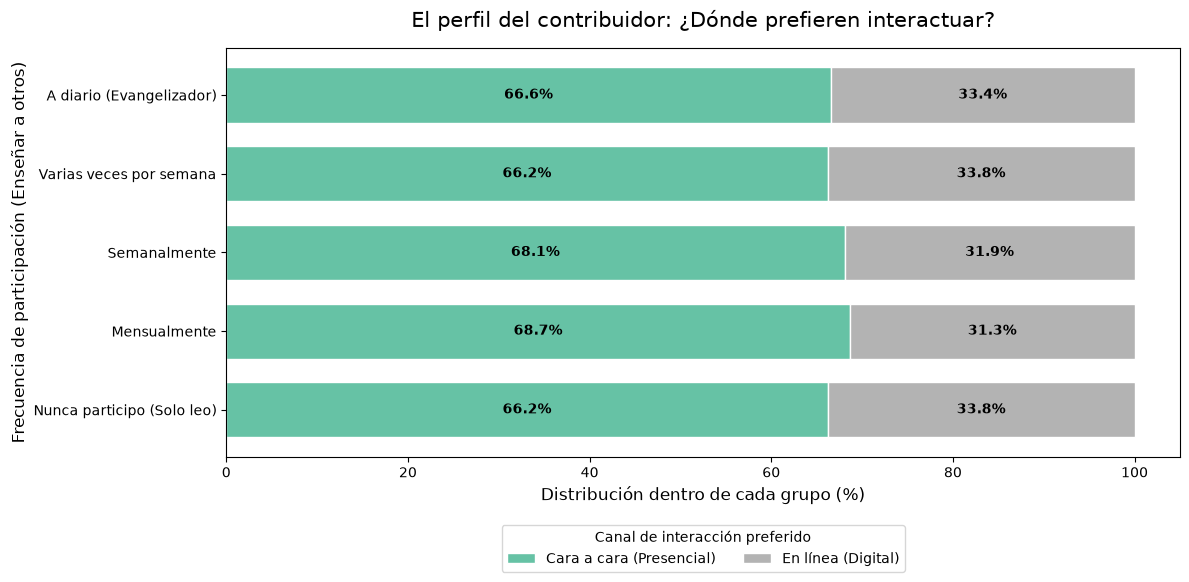

In [19]:
df_com = df_clean.dropna(subset=['SOPartFreq', 'Extraversion']).copy()

df_com['Extraversion_ES'] = df_com['Extraversion'].map(config.MAPEO_EXTRA)
df_com['SOPartFreq_ES'] = df_com['SOPartFreq'].map(config.MAPEO_SOPART)

orden_sopart = list(config.MAPEO_SOPART.values())
crosstab_extra = pd.crosstab(df_com['SOPartFreq_ES'], df_com['Extraversion_ES'], normalize='index') * 100
crosstab_extra = crosstab_extra.reindex(index=orden_sopart)

fig, ax2 = plt.subplots(figsize=(12, 6))
crosstab_extra.plot(
    kind='barh', stacked=True, ax=ax2, colormap='Set2', edgecolor='white', width=0.7
)

ax2.set_title('El perfil del contribuidor: ¿Dónde prefieren interactuar?', fontsize=15, pad=15)
ax2.set_xlabel('Distribución dentro de cada grupo (%)', fontsize=12)
ax2.set_ylabel('Frecuencia de participación (Enseñar a otros)', fontsize=12)
ax2.legend(title='Canal de interacción preferido', bbox_to_anchor=(0.5, -0.15), loc='upper center', ncol=2)

for c in ax2.containers:
    labels = [f'{v.get_width():.1f}%' if v.get_width() > 5 else '' for v in c]
    ax2.bar_label(c, labels=labels, label_type='center', color='black', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

Al observar la gráfica sobre las preferencias de interacción, nos encontramos con lo siguiente:

* El **66.6%** de estos perfiles altamente activos ("Evangelizadores") prefiere la interacción humana cara a cara.
* Los que nunca participan en foros y solo leen (66.2% presencial) tienen exactamente la misma preferencia por el trato humano que quienes participan varias veces por semana (66.2%). La variación entre todos los grupos es estadísticamente insignificante.

### 2.14 Redes sociales y los candidatos

Para que el framework **NetSTAFF** sea una herramienta de reclutamiento verdaderamente integral, no solo debe saber cómo evaluar a un candidato, sino también **dónde encontrarlo**. 

Esta gráfica nos permite ver qué redes sociales son las más populares entre los distintos candidatos del dataset, lo cual explica mucho de la forma en la que estos se entretienen. También nos ayuda a ver dónde se encuentra el talento, ya que gracias a esta gráfica, podremos buscar mejor a los distintos desarrolladores y, dependiendo de la filosofía y uso de cada una de las redes sociales, podemos saber a alto nivel que tipo de contenido pueden frecuentar.

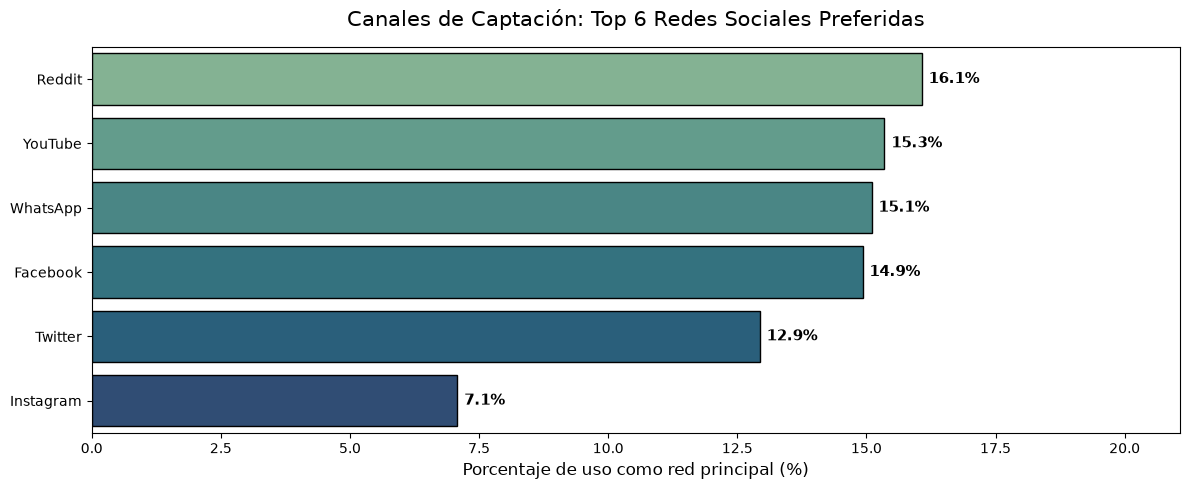

In [20]:
df_social = df_clean['SocialMedia'].dropna().value_counts(normalize=True).head(6) * 100
df_social.index = df_social.index.astype(str)

fig, ax3 = plt.subplots(figsize=(12, 5))

sns.barplot(x=df_social.values, y=df_social.index, palette='crest', edgecolor='black', ax=ax3)
ax3.set_title('Canales de Captación: Top 6 Redes Sociales Preferidas', fontsize=15, pad=15)
ax3.set_xlabel('Porcentaje de uso como red principal (%)', fontsize=12)
ax3.set_ylabel('')

for c in ax3.containers:
    ax3.bar_label(c, fmt='%.1f%%', padding=5, color='black', fontweight='bold', fontsize=11)
ax3.set_xlim(0, df_social.max() + 5)

plt.tight_layout()
plt.show()

En la gráfica podemos ver que reddit y youtube son las principales redes sociales que frecuentan los profesionales, mucho más que instagram por ejemplo, la cual es aproximadamente un 60% menos popular que las más visitadas.